[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Incertidumbre, intervalos de confianza y *bootstrap*.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Lunes 26 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo III: *Inferencia estadística*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En esta sesión se cuantificará la incertidumbre de una estimación: se simulará la distribución muestral con *NumPy*, se calcularán errores estándar e intervalos de confianza para medias y proporciones con *SciPy* y *statsmodels*, y se construirán intervalos *bootstrap* con `scipy.stats.bootstrap`, usando `penguins`. Al final se presenta la consigna del **Proyecto integrador**.

## 🎯 Objetivo de la sesión.

**Acompañar cada estimación con su incertidumbre, con fórmulas clásicas y con remuestreo, e interpretarla correctamente.**

Al terminar podrás:
1. Explicar la diferencia entre población, muestra y distribución muestral, y por qué el error estándar baja con √*n*.
2. Calcular intervalos de confianza para una media (fórmula *t*) y para una proporción (Wald, Wilson, Clopper-Pearson).
3. Construir intervalos *bootstrap* para la media, la mediana y la diferencia entre dos grupos.
4. Interpretar un intervalo de confianza sin las confusiones más comunes y elegir el método según los datos.

## 🗺️ Agenda (120 min).

| Min | Bloque |
|---|---|
| 10 | Retroalimentación de la Evaluación semanal 1 |
| 20 | 1. Población, muestra y distribución muestral |
| 25 | 2. Error estándar e intervalos de confianza |
| 30 | 3. *Bootstrap* |
| 15 | 4. Interpretación correcta de un IC y consigna del Proyecto integrador |
| 20 | 5. Ejercicio de la sesión y cierre |

🟢 = ejercicio básico · 🔴 = reto opcional

## 📚 Referencias.

* La generación de números aleatorios con `np.random.default_rng` se explica en [py311 · 04 Arreglos con contenido aleatorio](https://github.com/PythonistaMX/py311/blob/main/04_arreglos_con_contenido_aleatorio.ipynb) y los resúmenes con *NumPy* en [py311 · 07 Gestión y análisis de datos de *NumPy*](https://github.com/PythonistaMX/py311/blob/main/07_gestion_y_analisis_de_datos_de_numpy.ipynb).
* py311 no cubre inferencia, así que la referencia de la API es la documentación oficial: [*SciPy* · `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html), [*SciPy* · `bootstrap`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) y [*statsmodels* · `proportion_confint`](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html).

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3; si algo se ve distinto, se sigue lo que muestra este *notebook*.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluidos `stats` de *SciPy* y las funciones de *statsmodels* que se usarán, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.weightstats import DescrStatsW

* La siguiente celda leerá `penguins_limpio.csv` (o lo regenerará desde `penguins.csv` si no existe) y `titanic.csv`.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio)
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((342, 7), (891, 15))

---
## 0. Retroalimentación de la Evaluación semanal 1 (10 min).

El instructor comentará en vivo los resultados del grupo. Estos son los puntos que más conviene revisar en cualquier entrega de EDA descriptivo:

| Aspecto | Error frecuente | Lo que se espera |
|---|---|---|
| Calidad | Revisar faltantes pero no duplicados ni `dtypes` | Lista de verificación completa de la sesión 2 |
| Descripción | Reportar solo media y desviación estándar de `tip_pct`, que es asimétrica y tiene atípicos | Mediana e IQR, o ambas con la justificación |
| Agregación | Comparar medias por grupo sin el número de cuentas de cada grupo | Tabla con *n* por celda (en `tips`, las comidas son casi todas en jueves) |
| Gráficas | Barras de medias sin dispersión, ejes sin unidades | Diagramas de caja o puntos con dispersión; títulos con el hallazgo |
| Conclusiones | "Los fumadores dejan más propina porque…" | Lenguaje descriptivo: "en estos datos, la mediana fue…" |

Hoy se agrega la pieza que faltaba en la evaluación 1: **¿qué tan seguros estamos de esos números?**

---
## 1. Población, muestra y distribución muestral (20 min).

* **Población:** todos los individuos de interés (todos los pingüinos de esas colonias). Su media μ es desconocida.
* **Muestra:** los individuos medidos. Su media x̄ es un **estimador** de μ.
* **Distribución muestral:** cómo variaría x̄ si se repitiera el muestreo muchas veces. Su desviación estándar es el **error estándar** (EE).

Para **ver** la distribución muestral se necesita conocer la población. Por eso, solo en esta sección, se tratarán los 342 pingüinos con masa registrada como si fueran la población completa y se sacarán muchas muestras de ella.

* La siguiente celda definirá la población de juguete y su media y desviación estándar.

In [3]:
poblacion = pinguinos["body_mass_g"].dropna().to_numpy()
mu, sigma = poblacion.mean(), poblacion.std()
round(float(mu), 1), round(float(sigma), 1)

(4201.8, 800.8)

* La siguiente celda sacará 2,000 muestras de tamaño 25 y guardará la media de cada una.

In [4]:
medias_25 = rng.choice(poblacion, size=(2000, 25)).mean(axis=1)
round(float(medias_25.mean()), 1), round(float(medias_25.std()), 1)

(4207.2, 159.0)

* La siguiente celda comparará la distribución de la población con la distribución muestral de la media.

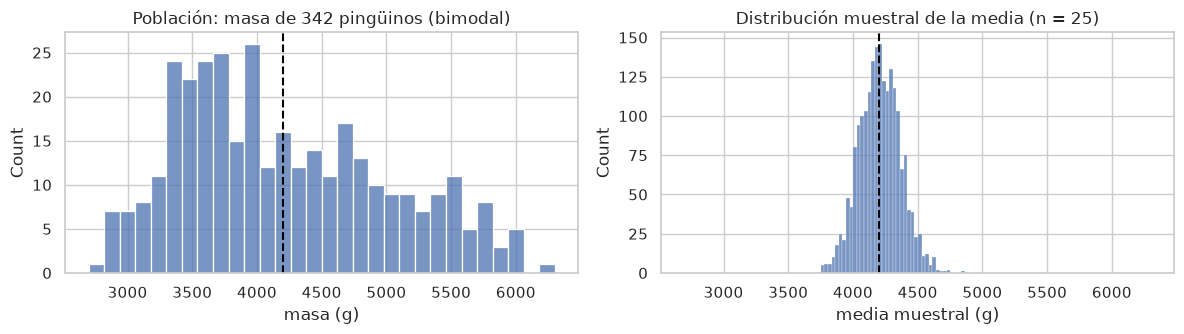

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
sns.histplot(poblacion, bins=30, ax=axes[0]).set(title="Población: masa de 342 pingüinos (bimodal)", xlabel="masa (g)")
sns.histplot(medias_25, bins=40, ax=axes[1]).set(title="Distribución muestral de la media (n = 25)", xlabel="media muestral (g)")
for ax in axes:
    ax.axvline(mu, color="black", linestyle="--")
plt.tight_layout()
plt.show()

Aunque la población es bimodal, las medias de muestras de 25 se distribuyen de forma casi normal alrededor de μ: es el **teorema central del límite**. Su dispersión, unos 160 g, es el error estándar.

### 1.1 El error estándar baja con √*n*.

Para la media, EE = σ / √*n*. Cuadruplicar la muestra reduce el error estándar **a la mitad**, no a la cuarta parte: la precisión cuesta cada vez más datos.

* La siguiente celda comparará el error estándar simulado con la fórmula σ / √n para tres tamaños de muestra.

In [6]:
pd.DataFrame({
    n: {"EE simulado": rng.choice(poblacion, size=(2000, n)).mean(axis=1).std(),
        "σ / √n": sigma / np.sqrt(n)}
    for n in [25, 100, 400]
}).T.round(1)

,EE simulado,σ / √n
25,164.0,160.2
100,78.7,80.1
400,40.0,40.0


### 🟢 Ejercicio 1 · ¿Media o mediana?

Con `poblacion`, saca 2,000 muestras de tamaño 25 (usa `generador = np.random.default_rng(401)`) y calcula para cada una la **media** y la **mediana**. ¿Cuál de los dos estimadores varía más de muestra a muestra? Compara sus desviaciones estándar y dibuja ambas distribuciones.

* La siguiente celda muestra una solución posible.

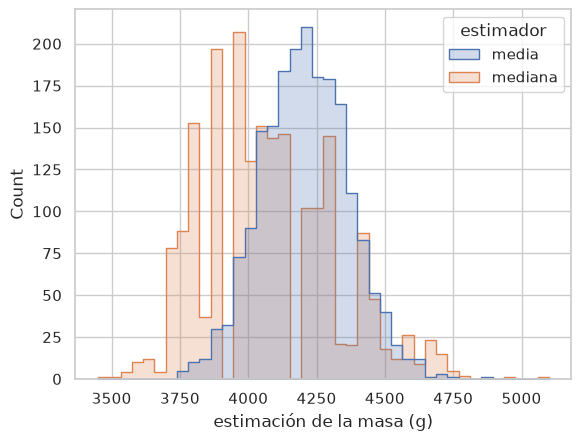

media      159.1
mediana    241.5
dtype: float64

In [7]:
generador = np.random.default_rng(401)
muestras = generador.choice(poblacion, size=(2000, 25))
estimadores = pd.DataFrame({"media": muestras.mean(axis=1), "mediana": np.median(muestras, axis=1)})
sns.histplot(estimadores.melt(var_name="estimador", value_name="valor"), x="valor", hue="estimador",
             element="step", bins=40)
plt.xlabel("estimación de la masa (g)")
plt.show()
estimadores.std().round(1)

**✅ Respuesta sugerida:**

La mediana varía más (su desviación estándar es mayor que la de la media, que ronda 160 g). En esta población bimodal la mediana "salta" entre los dos picos según cuántos Gentoo caigan en la muestra. La media es más eficiente cuando no hay atípicos; la mediana compensa ese costo cuando sí los hay.

---
## 2. Error estándar e intervalos de confianza (25 min).

En la práctica solo hay **una** muestra. El error estándar se estima con la desviación estándar muestral: EE = *s* / √*n*. Un **intervalo de confianza** (IC) del 95% para la media es:

```
x̄ ± t(0.975, n − 1) · s / √n
```

Donde:
* `t(0.975, n − 1)` es el cuantil de la distribución *t* de Student con *n* − 1 grados de libertad (≈ 1.98 para *n* = 123).
* `s / √n` es el error estándar estimado.

**Ejemplo:** desde aquí se vuelve a la situación real: los Gentoo medidos son una **muestra** de la población de Gentoo.

* La siguiente celda calculará el IC del 95% para la masa media de los Gentoo con la fórmula, paso a paso.

In [8]:
masa_gentoo = pinguinos.loc[pinguinos["species"] == "Gentoo", "body_mass_g"].dropna()
n = len(masa_gentoo)
media = masa_gentoo.mean()
error_estandar = masa_gentoo.std(ddof=1) / np.sqrt(n)
t_critico = stats.t.ppf(0.975, df=n - 1)
n, round(float(media), 1), round(float(error_estandar), 1), np.round([media - t_critico * error_estandar, media + t_critico * error_estandar], 1)

(123, 5076.0, 45.5, array([4986., 5166.]))

* La siguiente celda obtendrá el mismo intervalo con `stats.t.interval` de *SciPy* y con `DescrStatsW` de *statsmodels*.

In [9]:
con_scipy = stats.t.interval(0.95, df=n - 1, loc=media, scale=stats.sem(masa_gentoo))
con_statsmodels = DescrStatsW(masa_gentoo).tconfint_mean(alpha=0.05)
np.round(con_scipy, 1), np.round(con_statsmodels, 1)

(array([4986., 5166.]), array([4986., 5166.]))

### 2.1 Intervalos para una proporción.

Para una proporción *p̂* = *k* / *n* hay varios métodos (`proportion_confint(k, n, method=...)`):

| Método | `method=` | Comentario |
|---|---|---|
| Wald | `"normal"` | *p̂* ± 1.96·√(*p̂*(1 − *p̂*)/*n*). Simple, pero falla con *n* pequeño o *p̂* cerca de 0 o 1 |
| Wilson | `"wilson"` | Recomendado por defecto: buena cobertura incluso con *n* pequeño |
| Clopper-Pearson | `"beta"` | "Exacto": conservador (intervalos algo más anchos) |

* La siguiente celda calculará los tres intervalos para la tasa de supervivencia del Titanic.

In [10]:
sobrevivientes, pasajeros = int(titanic["survived"].sum()), len(titanic)
pd.DataFrame({metodo: proportion_confint(sobrevivientes, pasajeros, alpha=0.05, method=metodo)
              for metodo in ["normal", "wilson", "beta"]}, index=["inferior", "superior"]).T.round(3)

,inferior,superior
normal,0.352,0.416
wilson,0.352,0.416
beta,0.352,0.417


Con 891 pasajeros los tres métodos coinciden (≈ 35% a 42%). La decisión importa con muestras pequeñas.

**Decisión: ¿Wald o Wilson con pocos datos?** Con 2 éxitos en 30 casos, la fórmula de Wald da un límite inferior **negativo**, imposible para una proporción (`statsmodels` lo recorta a 0, lo que oculta el problema).

* La siguiente celda calculará Wald a mano y Wilson con *statsmodels* para 2 éxitos en 30.

In [11]:
p_gorro = 2 / 30
margen = 1.96 * np.sqrt(p_gorro * (1 - p_gorro) / 30)
{"Wald a mano": (round(float(p_gorro - margen), 3), round(float(p_gorro + margen), 3)),
 "Wilson": tuple(round(float(v), 3) for v in proportion_confint(2, 30, method="wilson"))}

{'Wald a mano': (-0.023, 0.156), 'Wilson': (0.018, 0.213)}

### 2.2 Consecuencia: ¿cuándo se puede confiar en la fórmula *t*?

El "95%" es una promesa sobre el **procedimiento**: si se repitiera el muestreo, 95% de los intervalos capturarían μ. Esa promesa depende de supuestos. Se simulará la **cobertura real** del IC *t* con dos poblaciones: la masa de los pingüinos (sin colas largas) y la tarifa del Titanic (muy asimétrica, con atípicos).

* La siguiente celda definirá `cobertura_t`, que saca muchas muestras, calcula el IC *t* de cada una y cuenta qué fracción contiene la media poblacional.

In [12]:
def cobertura_t(poblacion, n, repeticiones=2000, generador=rng):
    muestras = generador.choice(poblacion, size=(repeticiones, n))
    medias = muestras.mean(axis=1)
    errores = muestras.std(axis=1, ddof=1) / np.sqrt(n)
    t_critico = stats.t.ppf(0.975, df=n - 1)
    contiene = (medias - t_critico * errores <= poblacion.mean()) & (poblacion.mean() <= medias + t_critico * errores)
    return contiene.mean()

* La siguiente celda calculará la cobertura con muestras de 10, 30 y 100 en ambas poblaciones.

In [13]:
tarifas = titanic["fare"].to_numpy()
pd.DataFrame({n: {"masa (pingüinos)": cobertura_t(poblacion, n), "tarifa (Titanic)": cobertura_t(tarifas, n)}
              for n in [10, 30, 100]}).round(3)

,10,30,100
masa (pingüinos),0.940,0.952,0.947
tarifa (Titanic),0.799,0.844,0.910


Con la masa, la cobertura es ≈ 95% incluso con *n* = 10. Con la tarifa, un IC "del 95%" con *n* = 10 solo captura la media en torno a 80% de las veces, y aún con *n* = 100 se queda debajo de 95%. **Consecuencia:** con datos muy asimétricos y muestras pequeñas, el intervalo es demasiado estrecho y transmite una seguridad falsa. Conviene reportar la mediana con un IC *bootstrap*, transformar (logaritmo) o, al menos, advertirlo.

### 🟢 Ejercicio 2 · Supervivencia en tercera clase.

Calcula la tasa de supervivencia de los pasajeros de **tercera clase** con su IC del 95% por Wilson, y compárala con la de primera clase. ¿Se traslapan los intervalos?

* La siguiente celda muestra una solución posible.

In [14]:
por_clase = titanic.groupby("class")["survived"].agg(sobrevivientes="sum", pasajeros="count")
intervalos = [proportion_confint(f["sobrevivientes"], f["pasajeros"], method="wilson") for _, f in por_clase.iterrows()]
por_clase.assign(
    tasa=lambda d: d["sobrevivientes"] / d["pasajeros"],
    ic_inferior=[i[0] for i in intervalos],
    ic_superior=[i[1] for i in intervalos],
).round(3)

,sobrevivientes,pasajeros,tasa,ic_inferior,ic_superior
class,,,,,
First,136,216,0.630,0.563,0.691
Second,87,184,0.473,0.402,0.545
Third,119,491,0.242,0.207,0.282


**✅ Respuesta sugerida:**

En tercera clase sobrevivió 24.2% (IC 95% de Wilson ≈ 20.7% a 28.2%, con 491 pasajeros); en primera, 63.0% (≈ 56.4% a 69.1%). Los intervalos están muy lejos uno de otro: la diferencia no se explica por variación muestral.

### 🔴 Reto 1 · Cobertura de Wald y Wilson.

Simula 5,000 muestras de tamaño 20 de una población con proporción verdadera 0.10 (`generador.binomial(20, 0.10, size=5000)`, con `generador = np.random.default_rng(401)`). Para cada muestra calcula el IC de Wald y el de Wilson y estima la cobertura de cada método. ¿Cuál cumple mejor la promesa del 95%?

* La siguiente celda muestra una solución posible.

In [15]:
generador = np.random.default_rng(401)
exitos = generador.binomial(20, 0.10, size=5000)
cobertura = {}
for metodo in ["normal", "wilson"]:
    inferior, superior = proportion_confint(exitos, 20, method=metodo)
    cobertura[metodo] = float(((inferior <= 0.10) & (0.10 <= superior)).mean())
cobertura

{'normal': 0.8734, 'wilson': 0.9544}

**✅ Respuesta sugerida:**

Wald cubre bastante menos que 95% (cerca de 87%): cuando la muestra tiene 0 éxitos su intervalo es [0, 0] y nunca contiene 0.10. Wilson queda mucho más cerca de 95%. Por eso Wilson es la opción por defecto para proporciones.

---
## 3. *Bootstrap* (30 min).

El *bootstrap* estima la distribución muestral **sin fórmula**: trata la muestra como si fuera la población y la **remuestrea con reemplazo** muchas veces, calculando el estadístico en cada remuestra.

1. Remuestrear *n* valores con reemplazo de la muestra original.
2. Calcular el estadístico (media, mediana, diferencia…).
3. Repetir miles de veces; la dispersión de esos valores aproxima el error estándar y sus percentiles 2.5% y 97.5% dan un IC del 95% (**método percentil**).

* La siguiente celda hará un *bootstrap* a mano de la media de los Gentoo con 9,999 remuestras.

In [16]:
valores_gentoo = masa_gentoo.to_numpy()
remuestras = rng.choice(valores_gentoo, size=(9999, len(valores_gentoo)), replace=True)
medias_boot = remuestras.mean(axis=1)
round(float(medias_boot.std(ddof=1)), 1), np.percentile(medias_boot, [2.5, 97.5]).round(1)

(45.5, array([4987. , 5165.7]))

* La siguiente celda dibujará la distribución *bootstrap* con el intervalo percentil.

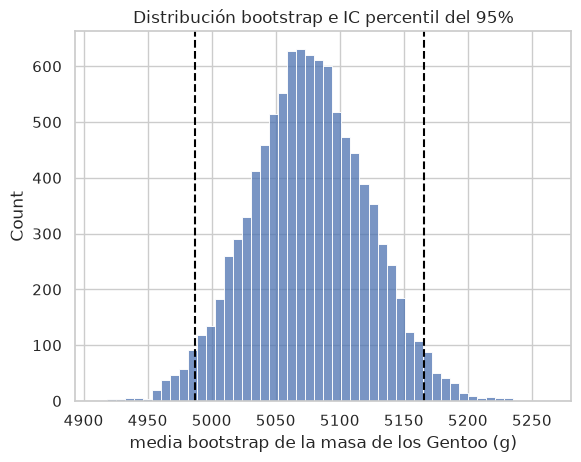

In [17]:
ax = sns.histplot(medias_boot, bins=50)
for limite in np.percentile(medias_boot, [2.5, 97.5]):
    ax.axvline(limite, color="black", linestyle="--")
ax.set(xlabel="media bootstrap de la masa de los Gentoo (g)", title="Distribución bootstrap e IC percentil del 95%")
plt.show()

### 3.1 `scipy.stats.bootstrap`.

```
stats.bootstrap((<muestra>,), <estadistico>, n_resamples=9999, confidence_level=0.95,
                method="BCa", random_state=401)
```

Donde:
* `<muestra>` va dentro de una tupla; para dos grupos se pasa `(<grupo_a>, <grupo_b>)`.
* `<estadistico>` es una función que acepta el argumento `axis` (como `np.mean` o `np.median`).
* `method` puede ser `"percentile"`, `"basic"` o `"BCa"` (por defecto), que corrige sesgo y asimetría.
* `random_state=401` hace reproducible el resultado.

* La siguiente celda calculará el IC *bootstrap* de la media de los Gentoo con los métodos percentil y BCa.

In [18]:
{metodo: np.round(stats.bootstrap((valores_gentoo,), np.mean, n_resamples=9999, method=metodo,
                                  random_state=401).confidence_interval, 1)
 for metodo in ["percentile", "BCa"]}

{'percentile': array([4990.4, 5164.4]), 'BCa': array([4990. , 5164.2])}

Con 123 Gentoo y una distribución casi simétrica, la fórmula *t* (≈ 4,986 a 5,166 g) y el *bootstrap* difieren en menos de 5 g en cada extremo. La ventaja del *bootstrap* aparece con estadísticos sin fórmula sencilla, como la mediana o una diferencia de medianas.

* La siguiente celda calculará un IC *bootstrap* para la **mediana** de la masa de los Gentoo.

In [19]:
ic_mediana = stats.bootstrap((valores_gentoo,), np.median, n_resamples=9999, method="percentile", random_state=401)
float(np.median(valores_gentoo)), np.round(ic_mediana.confidence_interval, 1)

(5000.0, array([4900., 5200.]))

### 3.2 Diferencia entre dos grupos.

Para una diferencia, la función recibe dos muestras y el `axis`. Cada grupo se remuestrea **por separado**, respetando su tamaño.

* La siguiente celda definirá `diferencia_medias` y calculará el IC *bootstrap* de la diferencia de masa media entre machos y hembras Gentoo.

In [20]:
def diferencia_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)

gentoo = pinguinos[pinguinos["species"] == "Gentoo"]
machos_gentoo = gentoo.loc[gentoo["sex"] == "Male", "body_mass_g"].to_numpy()
hembras_gentoo = gentoo.loc[gentoo["sex"] == "Female", "body_mass_g"].to_numpy()
ic_diferencia = stats.bootstrap((machos_gentoo, hembras_gentoo), diferencia_medias, n_resamples=9999,
                                method="percentile", random_state=401)
round(float(diferencia_medias(machos_gentoo, hembras_gentoo)), 1), np.round(ic_diferencia.confidence_interval, 1)

(805.1, array([698.9, 909.9]))

**Advertencia:** el *bootstrap* no crea información. Supone que la muestra representa bien a la población y, con muestras pequeñas o asimétricas, también **subcubre**. No corrige un sesgo de selección.

### 🟢 Ejercicio 3 · Mediana de la aleta de los Chinstrap.

Calcula un IC *bootstrap* del 95% (percentil, `random_state=401`) para la **mediana** de `flipper_length_mm` de los Chinstrap. Compáralo con el IC *t* de la media. ¿Por qué el intervalo de la mediana tiene límites "redondos"?

* La siguiente celda muestra una solución posible.

In [21]:
aleta_chinstrap = pinguinos.loc[pinguinos["species"] == "Chinstrap", "flipper_length_mm"].dropna().to_numpy()
ic_mediana_aleta = stats.bootstrap((aleta_chinstrap,), np.median, n_resamples=9999, method="percentile",
                                   random_state=401).confidence_interval
ic_media_aleta = DescrStatsW(aleta_chinstrap).tconfint_mean()
float(np.median(aleta_chinstrap)), np.round(ic_mediana_aleta, 1), np.round(ic_media_aleta, 1)

(196.0, array([194. , 197.5]), array([194.1, 197.5]))

**✅ Respuesta sugerida:**

La mediana es 196 mm, con IC *bootstrap* de 194 a 197.5 mm; el IC *t* de la media (195.8 mm) es casi igual, de 194.1 a 197.5 mm. Los límites de la mediana son "redondos" porque la aleta se registró en milímetros enteros: la mediana de cada remuestra solo puede ser un valor observado o el promedio de dos (de ahí el .5). La distribución *bootstrap* de la mediana es **discreta**, algo que conviene notar al reportarla.

### 🔴 Reto 2 · ¿El *bootstrap* rescata a la tarifa del Titanic?

Repite la simulación de cobertura de la sección 2.2 para la tarifa con *n* = 10, pero con el IC *bootstrap* percentil de la media (usa 300 muestras y 999 remuestras para que no tarde, con `generador = np.random.default_rng(401)`). ¿Mejora la cobertura respecto al IC *t*?

* La siguiente celda muestra una solución posible.

In [22]:
generador = np.random.default_rng(401)
media_tarifa = tarifas.mean()
aciertos = 0
for _ in range(300):
    muestra = generador.choice(tarifas, size=10)
    ic = stats.bootstrap((muestra,), np.mean, n_resamples=999, method="percentile",
                         random_state=generador).confidence_interval
    aciertos += ic.low <= media_tarifa <= ic.high
float(aciertos / 300)

0.79

**✅ Respuesta sugerida:**

No mejora: la cobertura sigue cerca de 80%, igual que con el IC *t*. Con 10 tarifas, la muestra casi nunca contiene a los pocos pasajeros de tarifas muy altas que elevan la media poblacional, y el *bootstrap* solo puede remuestrear lo que hay en la muestra. Con datos tan asimétricos y *n* pequeño conviene cambiar de estimador (mediana) o de escala (logaritmo), y advertir la incertidumbre.

---
## 4. Interpretación correcta de un IC (15 min).

| Afirmación | ¿Correcta? |
|---|---|
| "El procedimiento produce intervalos que capturan la media poblacional en 95% de las muestras repetidas." | ✅ |
| "Con los datos observados, valores de la media entre 4,986 y 5,166 g son compatibles con la muestra." | ✅ (lectura práctica) |
| "Hay 95% de probabilidad de que μ esté entre 4,986 y 5,166 g." | ❌ μ es fija; lo aleatorio es el intervalo |
| "El 95% de los Gentoo pesa entre 4,986 y 5,166 g." | ❌ Confunde el IC de la **media** con la dispersión de los **individuos** |
| "Si dos IC se traslapan, no hay diferencia." | ❌ Pueden traslaparse y la diferencia ser significativa; se calcula el IC **de la diferencia** |
| "Un IC más estrecho siempre es mejor." | ❌ Solo si el procedimiento cumple su cobertura (sección 2.2) |

### 🟢 Ejercicio 4 · Reformula.

Un compañero escribió: *"La masa media de los Gentoo es 5,076 g y hay 95% de probabilidad de que el valor real esté entre 4,986 y 5,166 g, así que casi todos los Gentoo pesan unos 5 kg."* Señala los dos errores y reescribe la frase.

**✅ Respuesta sugerida:**

1. La probabilidad del 95% no se refiere a μ, sino al procedimiento.
2. El IC describe la incertidumbre sobre la **media**, no el peso de los individuos: los Gentoo varían con una desviación estándar de unos 500 g.

**Reescritura:** "La masa media estimada de los Gentoo es 5,076 g (IC 95%: 4,986 a 5,166 g, *n* = 123). Los individuos varían bastante más: la desviación estándar es de unos 500 g."

### 📣 Proyecto integrador: consigna.

**Se publica hoy en Classroom** (el texto siguiente es la referencia). Forma parte de la **Evaluación semanal 2** (70 de 100 puntos), que cierra el **domingo 1 de noviembre, 11:59 pm (CDMX)**.

**Consigna:** un EDA completo en un *notebook* reproducible en *Codespaces*, más un informe de hallazgos de 2 a 4 páginas (sección Markdown final o HTML/PDF exportado con `nbconvert`).

**Datasets a elegir:** `diamonds` (*Seaborn*), Adult / Census Income (UCI), Bike Sharing (UCI), Wine Quality (UCI), o uno propio **aprobado por el instructor antes del martes 27 de octubre**.

**Requisitos mínimos:**
1. 2 o 3 preguntas de análisis.
2. Auditoría de calidad y tratamiento justificado.
3. Descripción de distribuciones y atípicos.
4. Al menos una comparación de grupos y una relación entre variables.
5. Al menos dos pruebas de hipótesis distintas (o una prueba y un *bootstrap*), con supuestos revisados y tamaño del efecto.
6. Informe con resumen ejecutivo y limitaciones.

**Entrega en Classroom:** el `.ipynb` ejecutado, el informe (`.html` o `.pdf`) y el enlace al repositorio de GitHub. En la sesión 7 se entrega la **plantilla** `proyecto/plantilla_proyecto_integrador.ipynb` con esta estructura ya armada.

**Rúbrica del Proyecto integrador (70 puntos):**

| Criterio | Puntos | Excelente |
|---|---|---|
| Preguntas y contexto | 6 | Preguntas claras y respondibles con los datos; fuente y sesgos posibles descritos |
| Calidad de datos | 10 | Auditoría completa; decisiones de limpieza e imputación justificadas y con su impacto evaluado |
| Descripción y visualización | 12 | Distribuciones, atípicos y relaciones bien descritos; gráficas efectivas y rotuladas |
| Inferencia | 16 | Pruebas adecuadas, supuestos revisados, IC o *bootstrap*, tamaño del efecto interpretado |
| Informe de hallazgos | 16 | Resumen ejecutivo claro; hallazgos en lenguaje llano con su incertidumbre; limitaciones; sin causalidad injustificada |
| Reproducibilidad | 10 | Corre de principio a fin en *Codespaces*; `requirements.txt`, semillas y estructura ordenada |

Escala por criterio: Excelente = 100% de los puntos, Suficiente ≈ 60%, Insuficiente = 0 a 30%.

---
## 5. Ejercicio de la sesión (20 min).

### 🟢 Ejercicio 5 · Masa media de los Gentoo: fórmula *t* y *bootstrap*.

Reporta en una tabla la masa media de los Gentoo con su IC del 95% por la fórmula *t* y por *bootstrap* (percentil y BCa, `random_state=401`), junto con el ancho de cada intervalo.

* La siguiente celda muestra una solución posible.

In [23]:
intervalos_gentoo = {"t": DescrStatsW(valores_gentoo).tconfint_mean()}
for metodo in ["percentile", "BCa"]:
    ic = stats.bootstrap((valores_gentoo,), np.mean, n_resamples=9999, method=metodo,
                         random_state=401).confidence_interval
    intervalos_gentoo[f"bootstrap {metodo}"] = (ic.low, ic.high)
pd.DataFrame(intervalos_gentoo, index=["inferior", "superior"]).T.assign(
    ancho=lambda d: d["superior"] - d["inferior"]).round(1)

,inferior,superior,ancho
t,4986.0,5166.0,180.0
bootstrap percentile,4990.4,5164.4,174.0
bootstrap BCa,4990.0,5164.2,174.2


### 🟢 Ejercicio 6 · Diferencia de medianas entre machos y hembras Gentoo.

Calcula la diferencia de **medianas** de masa entre machos y hembras Gentoo con su IC *bootstrap* percentil del 95%. ¿El intervalo incluye el 0? ¿Qué significa?

* La siguiente celda muestra una solución posible.

In [24]:
def diferencia_medianas(a, b, axis=-1):
    return np.median(a, axis=axis) - np.median(b, axis=axis)

ic_medianas = stats.bootstrap((machos_gentoo, hembras_gentoo), diferencia_medianas, n_resamples=9999,
                              method="percentile", random_state=401).confidence_interval
float(diferencia_medianas(machos_gentoo, hembras_gentoo)), np.round(ic_medianas, 1)

(800.0, array([650., 900.]))

**✅ Respuesta sugerida:**

Los machos Gentoo tienen una masa mediana 800 g mayor que las hembras, con IC 95% de 650 a 900 g. El intervalo está lejos de 0, así que la diferencia no se explica por variación muestral. Los límites salen en múltiplos de 50 g porque las masas se registraron redondeadas (a 25 o 50 g).

### 🔴 Reto 3 · ¿Y si se mezclan las especies?

Repite el ejercicio 6 con **todos** los pingüinos (sin separar por especie) y después dentro de cada especie. ¿Por qué la diferencia global no coincide con ninguna de las diferencias por especie? ¿Cuál reportarías?

* La siguiente celda muestra una solución posible.

In [25]:
filas = []
grupos = [("todas", pinguinos)] + [(especie, datos) for especie, datos in pinguinos.groupby("species")]
for nombre, datos in grupos:
    machos = datos.loc[datos["sex"] == "Male", "body_mass_g"].dropna().to_numpy()
    hembras = datos.loc[datos["sex"] == "Female", "body_mass_g"].dropna().to_numpy()
    ic = stats.bootstrap((machos, hembras), diferencia_medianas, n_resamples=9999, method="percentile",
                         random_state=401).confidence_interval
    filas.append({"grupo": nombre, "diferencia": diferencia_medianas(machos, hembras), "inferior": ic.low, "superior": ic.high})
pd.DataFrame(filas).set_index("grupo").round(1)

,diferencia,inferior,superior
grupo,,,
todas,650.0,450.0,875.0
Adelie,600.0,500.0,776.2
Chinstrap,400.0,150.0,550.0
Gentoo,800.0,650.0,900.0


**✅ Respuesta sugerida:**

Con todos juntos, la diferencia es 650 g (IC 450 a 875 g); por especie es 600 g en Adelie, 400 g en Chinstrap y 800 g en Gentoo. La cifra global no es un promedio de las tres: es la diferencia entre las medianas de dos distribuciones bimodales que mezclan especies, y por eso su intervalo es más ancho. Se reportan las diferencias **por especie**, porque la especie explica gran parte de la masa y la diferencia entre sexos no es igual en todas.

### 🟢 Ejercicio 7 · Comenta los resultados.

En 3 o 4 frases: ¿coinciden la fórmula *t* y el *bootstrap* para la media de los Gentoo? ¿Por qué? ¿Qué aporta el *bootstrap* en el ejercicio 6 que no daba la fórmula?

**✅ Respuesta sugerida:**

Sí: para la media de los Gentoo la fórmula *t* (4,986 a 5,166 g) y el *bootstrap* (≈ 4,990 a 5,164 g) prácticamente coinciden, porque *n* = 123 es grande y la distribución es casi simétrica, así que se cumplen los supuestos de la fórmula. El *bootstrap* aporta en el ejercicio 6 un intervalo para una **diferencia de medianas**, que no tiene una fórmula sencilla; además deja ver que la distribución de la mediana es discreta.

---
## ✅ Cierre.

**Hoy vimos:**
* Distribución muestral y error estándar: EE = σ / √*n*; cuadruplicar *n* reduce el EE a la mitad.
* IC *t* para la media (*SciPy* y *statsmodels*) e IC para proporciones (Wald, Wilson, Clopper-Pearson).
* La cobertura real depende de los supuestos: con datos muy asimétricos y *n* pequeño, el IC "del 95%" cubre bastante menos.
* *Bootstrap* con `scipy.stats.bootstrap`: percentil y BCa, para la media, la mediana y diferencias entre grupos.
* Cómo interpretar (y cómo no) un intervalo de confianza.

**Práctica (sin calificación):** terminar los ejercicios 🟢 y elegir el *dataset* del Proyecto integrador. Si es uno propio, pedir aprobación antes del martes 27 de octubre.

**Próxima sesión (mar 27 oct):** pruebas de hipótesis y tamaño del efecto (`06_pruebas_hipotesis_efecto.ipynb`).

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>